In [3]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt


In [4]:
data=pd.read_csv("Crop_recommendation.csv")

In [5]:
data.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [7]:
data.size

17600

In [19]:
data.shape

(2200, 8)

In [8]:
data.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [10]:
data["label"].unique()

array(['rice', 'maize', 'chickpea', 'kidneybeans', 'pigeonpeas',
       'mothbeans', 'mungbean', 'blackgram', 'lentil', 'pomegranate',
       'banana', 'mango', 'grapes', 'watermelon', 'muskmelon', 'apple',
       'orange', 'papaya', 'coconut', 'cotton', 'jute', 'coffee'],
      dtype=object)

In [13]:
data.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [15]:
data.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

In [16]:
data.dtypes

N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object

In [17]:
df = data.drop(columns=['label'])

In [18]:
df.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall'], dtype='object')

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
dtypes: float64(4), int64(3)
memory usage: 120.4 KB


Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')


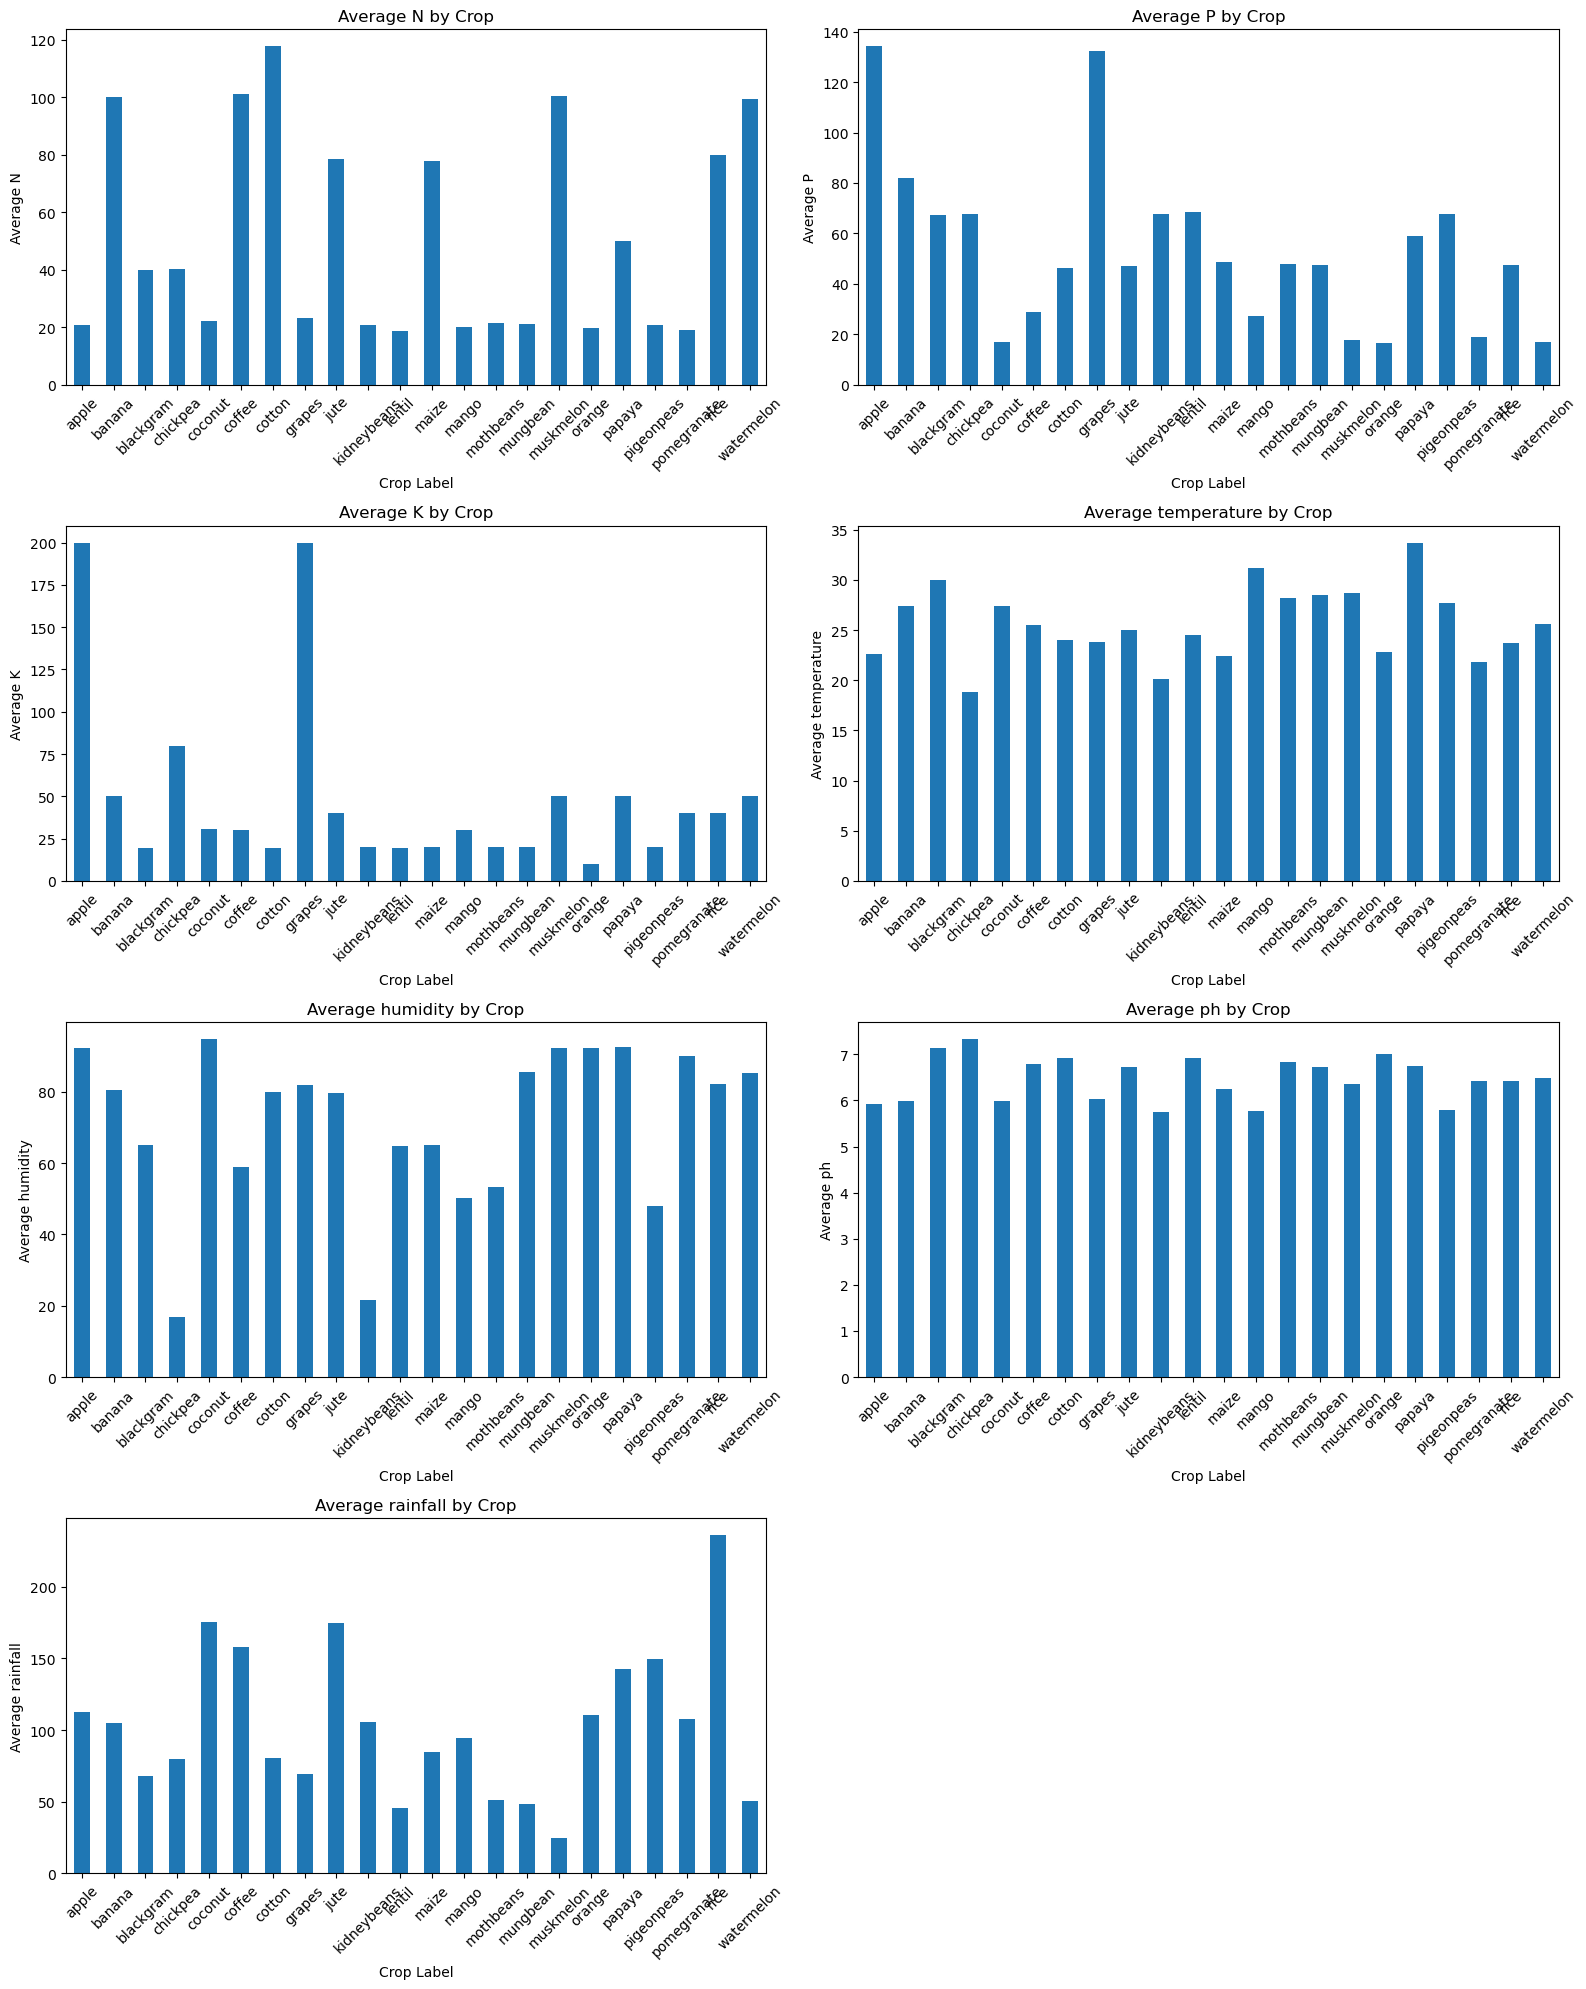

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
data = pd.read_csv("Crop_recommendation.csv")

# Check columns
print(data.columns)

# Features
columns = [
    'N',
    'P',
    'K',
    'temperature',
    'humidity',
    'ph',
    'rainfall'
]

# Create 4 rows × 2 columns
fig, axes = plt.subplots(4, 2, figsize=(16, 20))

# Convert 2D axes array into 1D
axes = axes.flatten()

for i, col in enumerate(columns):

    # Group crops by label and calculate
    # the average value of each feature
    data.groupby('label')[col].mean().plot(
        kind='bar',
        ax=axes[i]
    )

    axes[i].set_title(f'Average {col} by Crop')
    axes[i].set_xlabel('Crop Label')
    axes[i].set_ylabel(f'Average {col}')
    axes[i].tick_params(axis='x', rotation=45)

# There are 8 subplot spaces but only 7 features
# Remove the unused last subplot
fig.delaxes(axes[7])

plt.tight_layout()
plt.show()

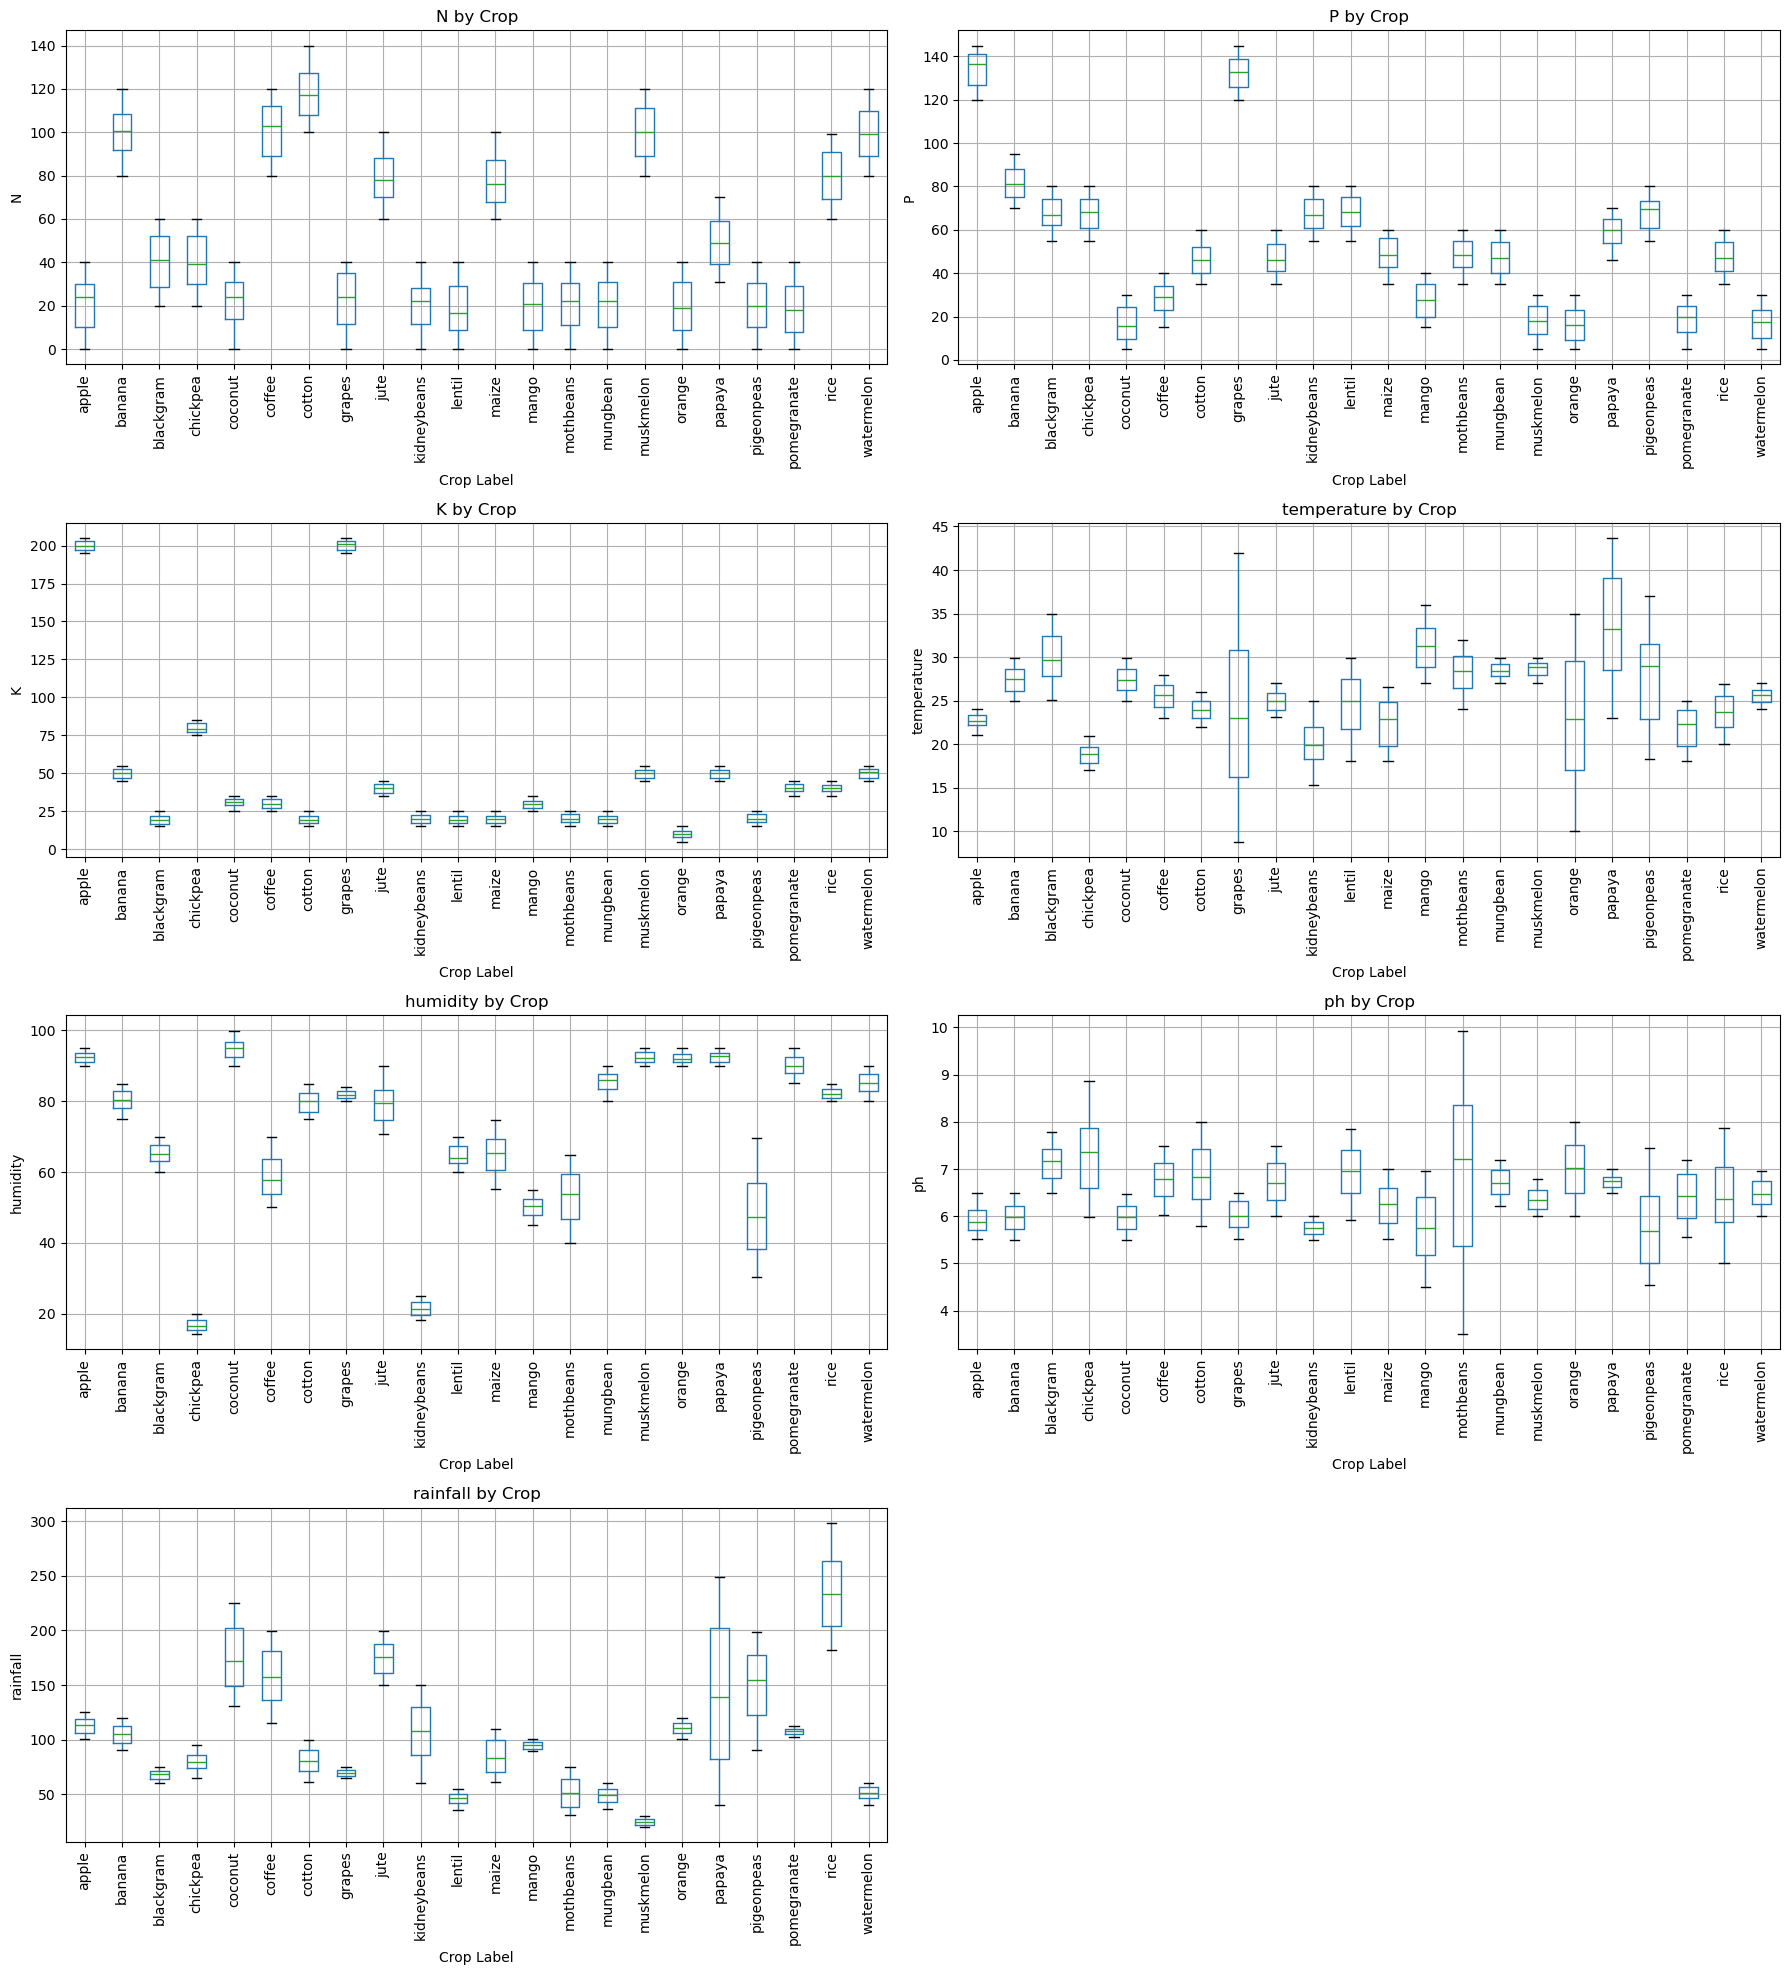

In [23]:
import matplotlib.pyplot as plt

# Numerical features
columns = [
    'N',
    'P',
    'K',
    'temperature',
    'humidity',
    'ph',
    'rainfall'
]

# 4 rows × 2 columns
fig, axes = plt.subplots(4, 2, figsize=(18, 20))

axes = axes.flatten()

for i, col in enumerate(columns):

    # Boxplot of each feature grouped by crop label
    data.boxplot(
        column=col,
        by='label',
        ax=axes[i]
    )

    axes[i].set_title(f'{col} by Crop')
    axes[i].set_xlabel('Crop Label')
    axes[i].set_ylabel(col)
    axes[i].tick_params(axis='x', rotation=90)

# Remove unused 8th subplot
fig.delaxes(axes[7])

# Remove automatic pandas title
plt.suptitle('')

plt.tight_layout()
plt.show()

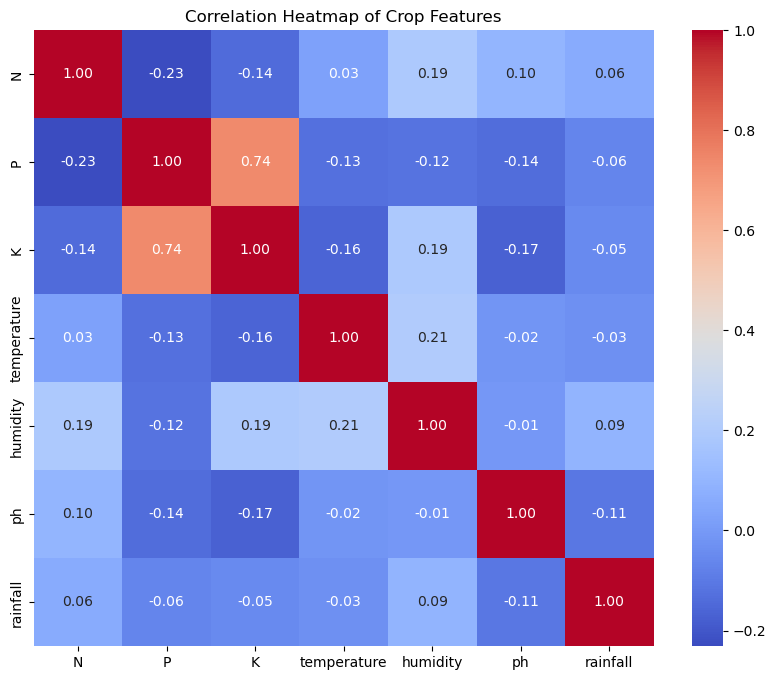

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    data.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Crop Features')
plt.show()

In [25]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall
0,90,42,43,20.879744,82.002744,6.502985,202.935536
1,85,58,41,21.770462,80.319644,7.038096,226.655537
2,60,55,44,23.004459,82.320763,7.840207,263.964248
3,74,35,40,26.491096,80.158363,6.980401,242.864034
4,78,42,42,20.130175,81.604873,7.628473,262.717340


In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Select features
X = data[['N', 'P', 'K', 'temperature',
          'humidity', 'ph', 'rainfall']]

# Create scaler
scaler = StandardScaler()

# Scale features
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

X_scaled.head()

,N,P,K,temperature,humidity,ph,rainfall
0,1.068797,-0.344551,-0.101688,-0.935587,0.472666,0.043302,1.810361
1,0.933329,0.140616,-0.141185,-0.759646,0.397051,0.734873,2.242058
2,0.255986,0.049647,-0.081939,-0.515898,0.486954,1.771510,2.921066
3,0.635298,-0.556811,-0.160933,0.172807,0.389805,0.660308,2.537048
4,0.743673,-0.344551,-0.121436,-1.083647,0.454792,1.497868,2.898373


In [33]:
X = X_scaled
y = data['label']

In [35]:
from sklearn.model_selection import train_test_split



X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [37]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [38]:
y_pred = model.predict(X_test_scaled)

In [39]:
from sklearn.metrics import accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9727272727272728


In [41]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

print("Baseline Accuracy:",
      accuracy_score(y_test, y_pred_baseline))

Baseline Accuracy: 0.045454545454545456


In [42]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

print("Naive Bayes Accuracy:",
      accuracy_score(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.9954545454545455


In [43]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_dt))

Decision Tree Accuracy: 0.9795454545454545


In [44]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy: 0.9954545454545455


In [45]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

svm_model = SVC()

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

print("SVM Accuracy:",
      accuracy_score(y_test, y_pred_svm))

SVM Accuracy: 0.9840909090909091


In [46]:
print("Baseline       :", accuracy_score(y_test, y_pred_baseline))
print("Naive Bayes    :", accuracy_score(y_test, y_pred_nb))
print("Decision Tree  :", accuracy_score(y_test, y_pred_dt))
print("Random Forest  :", accuracy_score(y_test, y_pred_rf))
print("SVM            :", accuracy_score(y_test, y_pred_svm))

Baseline       : 0.045454545454545456
Naive Bayes    : 0.9954545454545455
Decision Tree  : 0.9795454545454545
Random Forest  : 0.9954545454545455
SVM            : 0.9840909090909091


In [49]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bag_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    random_state=42
)

In [48]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print("Fold Accuracies:", scores)
print("Mean Accuracy:", scores.mean())
print("Standard Deviation:", scores.std())


Fold Accuracies: [0.99772727 0.99318182 0.99772727 0.99545455 0.98863636]
Mean Accuracy: 0.9945454545454545
Standard Deviation: 0.003401506715249021


In [53]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bag_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    random_state=42
)

In [57]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Create Bagging model
bag_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42
)

# 2. Train
bag_model.fit(X_train, y_train)

# 3. Predict
y_pred_bag = bag_model.predict(X_test)

# 4. Check train and test accuracy
train_accuracy = bag_model.score(X_train, y_train)
test_accuracy = accuracy_score(y_test, y_pred_bag)

print("Train Accuracy:", train_accuracy)
print("Test Accuracy :", test_accuracy)

Train Accuracy: 1.0
Test Accuracy : 0.990909090909091


In [ ]:

# 5. Detailed evaluation
print("\nClassification Report:")
print(classiication_report(y_test, y_pred_bag))


Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.95      0.97        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
   

In [59]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

bag_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),
    n_estimators=100,
    max_samples=0.8,
    bootstrap=True,
    random_state=42
)

# Train
bag_model.fit(X_train, y_train)

# Predict
y_pred_bag = bag_model.predict(X_test)

# Evaluate
print("Train Accuracy:",
      bag_model.score(X_train, y_train))

print("Test Accuracy:",
      accuracy_score(y_test, y_pred_bag))

Train Accuracy: 0.9965909090909091
Test Accuracy: 0.9954545454545455


In [60]:
import pickle

# Save Bagging model
with open("bagging_model.pkl", "wb") as f:
    pickle.dump(bag_model, f)

# Save StandardScaler
with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

print("Model and scaler saved successfully.")

Model and scaler saved successfully.
